# 02 – Logistic Regression
Predicts whether a patient has gallstones (0) or not (1)

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 0. What is logistic regression
Logistic regression is a classification model that predicts the probability that an observation belongs to one of two classes. The model gives each feature a weight and adds the weighted values together into a single number.

$$z = b_0 + b_1 x_1 + b_2 x_2 + \dots$$
 
 
Since $z$ can be any number, the sigmoid function, $P = \frac{1}{1 + e^{-z}}$, is used to turn it into a probability between 0 and 1. If the probability is above 0.5, the observation is assigned to class 1, otherwise to class 0.

In this project, each observation is a patient, and the two classes are gallstones (0) and no gallstones (1). The features are the patients demographic, body-composition and laboratory measurements, and the coefficients show which of these clinical characteristics the model relies on most when predicting gallstone disease. The plot below shows the sigmoid function, with the 0.5 threshold as a dashed line.

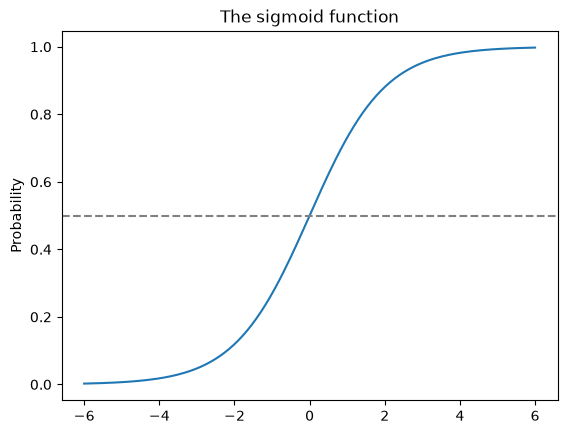

In [13]:
z = np.linspace(-6, 6, 200)                         # 200 values from -6 to 6 for a smooth curve
sigmoid = 1 / (1 + np.exp(-z))                      # The sigmoid function

plt.plot(z, sigmoid)
plt.axhline(0.5, color="grey", linestyle="--")      # Threshold line at 0.5
plt.ylabel("Probability")                           # Probability of gallestone 
plt.title("The sigmoid function")
plt.show()

## 1. Shared data preparation
The data loading and train/test split are copied from `01_exploration`, so this model is trained and tested on the same basis as the other models in the group.

In [14]:
from sklearn.model_selection import train_test_split

dataframe = pd.read_excel("../data/dataset.xlsx")
print(dataframe["Gallstone Status"].value_counts())  # Patients in each class

X = dataframe.drop(columns=["Gallstone Status"])     # All features
y = dataframe["Gallstone Status"]                    # The answer we want to predict

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,                                   # 20 % is kept aside as test data
    stratify=y,                                      # Same share of sick/healthy in train and test
    random_state=42                                  # Same split every time
)
print("Training:", X_train.shape, " Test:", X_test.shape)

Gallstone Status
0    161
1    158
Name: count, dtype: int64
Training: (255, 38)  Test: (64, 38)


## 2. Create and train the model

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([                                  # Make StandardScaler and LogisticRegression run in order
    ("scaler", StandardScaler()),                   # Puts all features on the same scale
    ("logreg", LogisticRegression())                # Makes a model that weights each feature and predicts the probability of gallstone disease
])

model.fit(X_train, y_train)                         # Trains the model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](38,)","['Age','Gender','Comorbidity',...,'C-Reactive Protein (CRP)', 'Hemoglobin (HGB)','Vitamin D']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,38
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 3. Predictions on the test data

In [16]:
predictions = model.predict(X_test)                 # Answer: 0 or 1
probabilities = model.predict_proba(X_test)         # Column 0 = gallstones, column 1 = no gallstones

pd.DataFrame({                                      # Table of the first 10 test patients
    "Actual": y_test.values,
    "Predicted": predictions,
    "P(gallstones)": probabilities[:, 0].round(2)
}).head(10)

,Actual,Predicted,P(gallstones)
0,1,1,0.14
1,1,1,0.00
2,0,0,0.98
3,0,0,0.91
4,0,0,1.00
5,0,0,0.97
6,1,1,0.15
7,1,1,0.39
8,1,1,0.32
9,1,1,0.00


## 4. Evaluation
Precision, recall and F1 use pos_label=0, because 0 = gallstones is the class we want to find.

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

accuracy  = accuracy_score(y_test, predictions)                   # Share of correct answers overall
precision = precision_score(y_test, predictions, pos_label=0)     # Said gallstones: how often right?
recall    = recall_score(y_test, predictions, pos_label=0)        # Had gallstones: how many found?
f1        = f1_score(y_test, predictions, pos_label=0)            # Balance of precision and recall
roc_auc   = roc_auc_score(y_test, probabilities[:, 1])            # Separation: 0.5 = guessing, 1 = perfect

print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1       :", round(f1, 3))
print("ROC-AUC  :", round(roc_auc, 3))

train_accuracy = accuracy_score(y_train, model.predict(X_train))  # Overfitting check (lecture 09)
print("\nTraining accuracy:", round(train_accuracy, 3))

Accuracy : 0.781
Precision: 0.765
Recall   : 0.812
F1       : 0.788
ROC-AUC  : 0.883

Training accuracy: 0.859


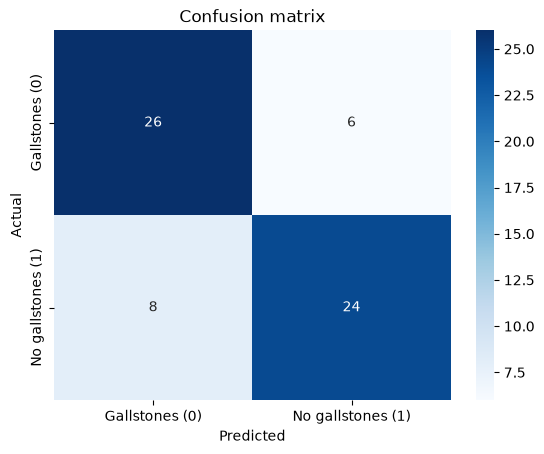

From the matrix we see that:
26 patients had gallstones and were predicted to have gallstones.
24 patients were healthy and were predicted to be healthy.
6 patients were predicted healthy, but had gallstones.
8 patients were predicted to have gallstones, but were healthy.


In [18]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predictions)          # Rows = actual, columns = predicted
labels = ["Gallstones (0)", "No gallstones (1)"]

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.show()

Gallstones = cm[0, 0]                               # Had gallstones, predicted gallstones
Healthy = cm[1, 1]                                  # Healthy, predicted healthy
missed = cm[0, 1]                                   # Had gallstones, predicted healthy
false_alarm = cm[1, 0]                              # Healthy, predicted gallstones
print("From the matrix we see that:")
print(Gallstones, "patients had gallstones and were predicted to have gallstones.")
print(Healthy, "patients were healthy and were predicted to be healthy.")
print(missed, "patients were predicted healthy, but had gallstones.")
print(false_alarm, "patients were predicted to have gallstones, but were healthy.")

## 5. Cross-validation
The test set has only 64 patients, so the result can be good or bad just by luck. Therefore is cross-validation is used to get a more trustworthy result. 

Cross-validation splits the training data into 5 parts and trains the model 5 times, each time on 4 parts, and tests it on the last part.

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)                    # 5 parts, same split every time

cv_accuracy = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")  # Accuracy in each of the 5 folds
cv_roc_auc  = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")   # ROC-AUC in each of the 5 folds

print("Accuracy per fold:", cv_accuracy.round(3))
print("Accuracy mean    :", round(cv_accuracy.mean(), 3), "±", round(cv_accuracy.std(), 3))
print("ROC-AUC per fold :", cv_roc_auc.round(3))
print("ROC-AUC mean     :", round(cv_roc_auc.mean(), 3), "±", round(cv_roc_auc.std(), 3))

Accuracy per fold: [0.667 0.784 0.647 0.765 0.843]
Accuracy mean    : 0.741 ± 0.074
ROC-AUC per fold : [0.763 0.848 0.754 0.851 0.932]
ROC-AUC mean     : 0.83 ± 0.066


## 6. Interpreting the coefficients
The data is scaled, so the coefficients can be compared directly. A larger number means a more important feature.

- Negative coefficient: a higher value gives a higher chance of gallstones
- Positive coefficient: a higher value gives a lower chance of gallstones

In [20]:
coefficients = model.named_steps["logreg"].coef_[0]                           # One weight per feature

coef_table = pd.DataFrame({"Feature": X.columns, "Coefficient": coefficients.round(3)})
coef_table = coef_table.sort_values("Coefficient", key=abs, ascending=False)  # Most important first
coef_table

,Feature,Coefficient
35,C-Reactive Protein (CRP),1.532
1,Gender,-1.345
18,Bone Mass (BM),-1.313
12,Intracellular Water (ICW),0.975
30,Aspartat Aminotransferaz (AST),-0.932
37,Vitamin D,-0.913
13,Extracellular Fluid/Total Body Water (ECF/TBW),-0.815
5,Hyperlipidemia,0.809
21,Total Fat Content (TFC),-0.738
0,Age,0.736


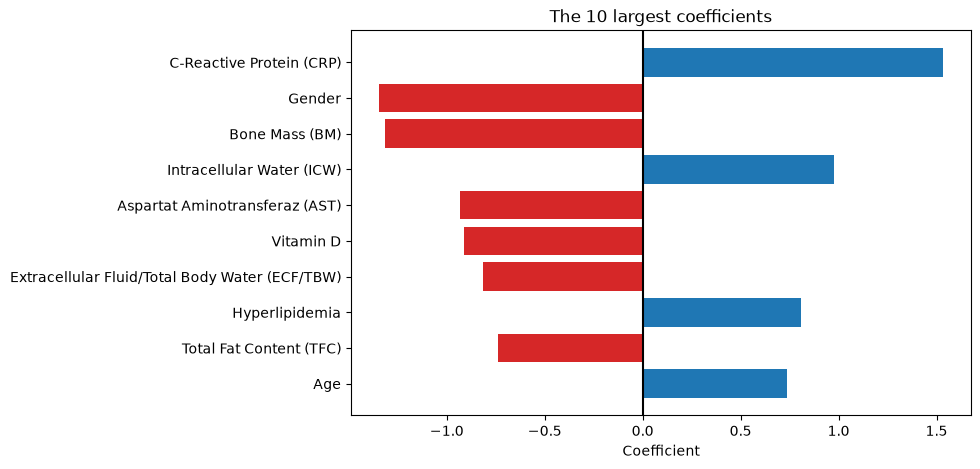

In [21]:
top10 = coef_table.head(10)                                                  # The 10 most important features
colors = ["tab:red" if c < 0 else "tab:blue" for c in top10["Coefficient"]]  # Red = more gallstones, blue = fewer

plt.figure(figsize=(8, 5))
plt.barh(top10["Feature"], top10["Coefficient"], color=colors)
plt.gca().invert_yaxis()                                                     # Most important at the top
plt.axvline(0, color="black")                                                # Line at 0
plt.xlabel("Coefficient")
plt.title("The 10 largest coefficients")
plt.show()

Interpretation: CRP, gender and bone mass have the largest coefficients. 

Higher bone mass, AST and vitamin D are associated with a higher chance of gallstones, while higher CRP and intracellular water are associated with a lower chance.

## Summary
The main results collected, for comparison with the other models in `05_comparison`.

In [22]:
pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "CV accuracy", "CV ROC-AUC"],
    "Logistic Regression": np.round([accuracy, precision, recall, f1, roc_auc,
                                     cv_accuracy.mean(), cv_roc_auc.mean()], 3)
})

,Metric,Logistic Regression
0,Accuracy,0.781
1,Precision,0.765
2,Recall,0.812
3,F1,0.788
4,ROC-AUC,0.883
5,CV accuracy,0.741
6,CV ROC-AUC,0.830
